In [31]:
import torch
import torch.nn.functional as F
import pandas as pd
from puck2vec import Puck2Vec
from puck2vec_dataset import SeqDataset



In [32]:
df=pd.read_csv("processed_ppt.csv")


In [34]:
LR = 1e-4
WEIGHT_DECAY = 1e-3
BATCH_SIZE = 32
MAX_EPOCHS = 64
PATIENCE = 5
VAL_FRAC = 0.1
EPV_WEIGHT = 0
PLAYER_DIM = 256
TRANSFORMER_DIM = 512
TRANS_LAYERS = 4
TRANS_HEADS = 4
SWAP_P = 0
SEED = 0
L2_WEIGHT = 0
DEVICE = "cuda"


dataset = SeqDataset(df, n_frames=40)
model=Puck2Vec(n_players = dataset.n_players, player_dim=PLAYER_DIM,n_frames=40)

In [35]:
import copy
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split

torch.manual_seed(SEED)
n_val = int(len(dataset) * VAL_FRAC)
train_set, val_set = random_split(dataset, [len(dataset) - n_val, n_val])
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)

model = Puck2Vec(n_players=dataset.n_players, player_dim=PLAYER_DIM, n_frames=dataset.n_frames,
                 transformer_dim=TRANSFORMER_DIM, trans_layers=TRANS_LAYERS, trans_heads=TRANS_HEADS).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

def batch_loss(batch, swap_p=0.0):
    b = {k: v.to(DEVICE) for k, v in batch.items()}
    # randomly replace player embeddings with their generic position embedding so those get trained too
    swap = torch.rand(b["player_ids"].shape, device=DEVICE) < swap_p if swap_p > 0 else None
    move_logits, v_logits = model(playerIds=b["player_ids"], player_pos=b["player_pos"],
                                  player_x=b["x"], player_y=b["y"], off=b["off"],
                                  player_dxs=b["dx"], player_dys=b["dy"],
                                  puck_x=b["puck_x"], puck_y=b["puck_y"])
    move_loss = F.cross_entropy(move_logits.flatten(0, 2), b["move"].flatten())
    goal = b["goal"][:, None].expand_as(v_logits[..., 0])  # one label per shot, repeated for every frame
    epv_loss = F.binary_cross_entropy_with_logits(v_logits[..., 0], goal)
    return move_loss + EPV_WEIGHT * epv_loss

history = {"train": [], "val": []}
best_val, best_state, bad_epochs = float("inf"), None, 0

for epoch in range(MAX_EPOCHS):
    model.train()
    total = 0.0
    for i, batch in enumerate(train_loader):
        loss = batch_loss(batch, swap_p=SWAP_P)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item()
        print(f"\repoch {epoch + 1} | batch {i + 1}/{len(train_loader)} | loss {loss.item():.4f}", end="")
    train_loss = total / len(train_loader)

    model.eval()
    with torch.no_grad():
        val_loss = sum(batch_loss(batch).item() for batch in val_loader) / len(val_loader)

    history["train"].append(train_loss)
    history["val"].append(val_loss)
    print(f"\repoch {epoch + 1} | train {train_loss:.4f} | val {val_loss:.4f}" + " " * 20)

    if val_loss < best_val:
        best_val, best_state, bad_epochs = val_loss, copy.deepcopy(model.state_dict()), 0
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"early stopping, val loss hasn't improved in {PATIENCE} epochs")
            break

model.load_state_dict(best_state)  # keep the best weights on held-out data
print(f"best val loss {best_val:.4f}")

epoch 1 | train 3.0495 | val 2.8384                    
epoch 2 | train 2.6934 | val 2.5554                    
epoch 3 | train 2.2545 | val 1.7838                    
epoch 4 | train 1.5962 | val 1.2986                    
epoch 5 | train 1.2697 | val 1.0322                    
epoch 6 | train 1.0828 | val 0.8997                    
epoch 7 | train 0.9556 | val 0.8013                    
epoch 8 | train 0.8576 | val 0.7452                    
epoch 9 | train 0.8002 | val 0.7065                    
epoch 10 | train 0.7590 | val 0.6581                    
epoch 11 | train 0.7188 | val 0.6807                    
epoch 12 | train 0.6914 | val 0.6171                    
epoch 13 | train 0.6696 | val 0.5954                    
epoch 14 | train 0.6492 | val 0.5804                    
epoch 15 | train 0.6365 | val 0.6160                    
epoch 16 | train 0.6256 | val 0.5601                    
epoch 17 | train 0.6179 | val 0.5501                    
epoch 18 | train 0.5977 | val 0.5480    

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
torch.save({"model": model, "player_index": dataset.player_index},"/content/drive/MyDrive/puck2vec.pth")

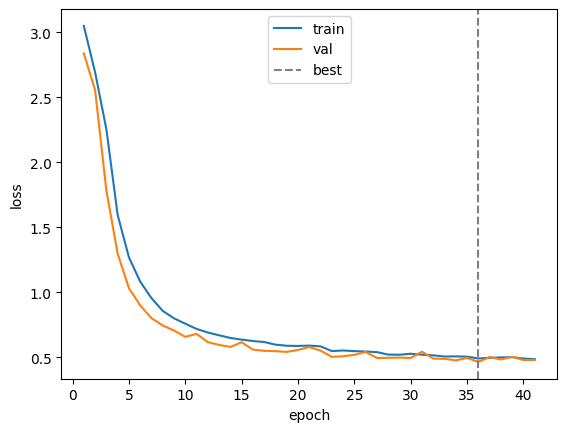

In [38]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train"]) + 1)
plt.plot(epochs, history["train"], label="train")
plt.plot(epochs, history["val"], label="val")
plt.axvline(int(torch.tensor(history["val"]).argmin()) + 1, color="gray", linestyle="--", label="best")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()